# 03 · Modelado — pronóstico day-ahead del PEND (MDA)

**Tarea:** el día D, con la información publicada hasta ese momento, pronosticar las 24 horas del precio MDA del día D+1.

El MDA de D se publica en D−1, así que al pronosticar D+1 se conoce el día D completo y nada más.
Para la hora *h* de D+1, el dato más reciente disponible es la hora 24 del día D: **cualquier lag menor a 24 h es fuga de información**.
Todas las variables se construyen con desplazamientos de 24 h o más.

**Validación:** backtest con origen móvil mensual sobre los últimos 12 meses. Cada mes se reentrena con todo lo anterior y se pronostica el mes completo.

In [2]:
pip install lightgbm scipy

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 1.9 MB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 2.2 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.1 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import time
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dateutil.easter import easter
from scipy import stats
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")

DATA = Path("data")
OUT = Path("resultados")
OUT.mkdir(exist_ok=True)

TEST_INICIO = pd.Timestamp("2025-11-01")
TEST_FIN = pd.Timestamp("2026-10-31 23:00")
TRAIN_DESDE = pd.Timestamp("2022-01-01")
ZONAS_FOCO = ["MONTERREY", "MERIDA", "HERMOSILLO"]

PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2", "axes.labelcolor": "#52514e",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.6,
    "axes.prop_cycle": plt.cycler(color=PALETA),
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "lines.linewidth": 1.6, "legend.frameon": False,
})

df = pd.read_parquet(DATA / "pend_sin_mda_clean.parquet").sort_values(["clave", "timestamp"]).reset_index(drop=True)
df = df[df.timestamp <= TEST_FIN]
ZONAS = sorted(df.clave.unique())
print(df.shape, df.timestamp.min(), "→", df.timestamp.max())

(684480, 7) 2017-01-27 00:00:00 → 2026-10-31 23:00:00


## 1. Calendario y festivos

In [5]:
def lunes_n(anio, mes, n):
    d = pd.Timestamp(anio, mes, 1)
    d += pd.Timedelta(days=(7 - d.dayofweek) % 7)
    return d + pd.Timedelta(weeks=n - 1)

def festivos_mx(anios):
    f = []
    for a in anios:
        pascua = pd.Timestamp(easter(a))
        f += [pd.Timestamp(a, 1, 1), lunes_n(a, 2, 1), lunes_n(a, 3, 3), pd.Timestamp(a, 5, 1),
              pd.Timestamp(a, 9, 16), lunes_n(a, 11, 3), pd.Timestamp(a, 12, 25),
              pascua - pd.Timedelta(days=3), pascua - pd.Timedelta(days=2)]
    return pd.DatetimeIndex(f).normalize()

FESTIVOS = festivos_mx(range(2016, 2028))
FESTIVOS[FESTIVOS.year == 2026]

DatetimeIndex(['2026-01-01', '2026-02-02', '2026-03-16', '2026-05-01',
               '2026-09-16', '2026-11-16', '2026-12-25', '2026-04-02',
               '2026-04-03'],
              dtype='datetime64[us]', freq=None)

## 2. Variables

Target: `y = asinh(precio / m_z)`, con `m_z` la mediana de la zona calculada solo con datos anteriores al periodo de prueba.

In [6]:
MEDIANA = df[df.timestamp < TEST_INICIO].groupby("clave")["precio"].median()

def construir_features(df):
    d = df.copy()
    d["m"] = d["clave"].map(MEDIANA)
    d["y"] = np.arcsinh(d["precio"] / d["m"])
    d["fecha"] = d["timestamp"].dt.normalize()
    g = d.groupby("clave", sort=False)

    for k in (24, 48, 72, 96, 120, 144, 168, 336):
        d[f"y_lag{k}"] = g["y"].shift(k)
    d["y_mean_mismahora_7d"] = d[[f"y_lag{k}" for k in (24, 48, 72, 96, 120, 144, 168)]].mean(axis=1)
    for c in ("energia", "congestion", "perdidas"):
        d[f"{c}_lag24"] = g[c].shift(24) / d["m"]
    d["energia_lag168"] = g["energia"].shift(168) / d["m"]

    dia = d.groupby(["clave", "fecha"])["y"].agg(["mean", "max", "min", "std", "last"])
    dia = dia.groupby(level=0).shift(1).add_prefix("dprev_")
    dia["dprev_mean_7d"] = dia.groupby(level=0)["dprev_mean"].transform(lambda s: s.rolling(7, min_periods=1).mean())
    d = d.join(dia, on=["clave", "fecha"])

    sistema = d.groupby("timestamp")["y_lag24"].mean().rename("sis_y_lag24")
    d = d.join(sistema, on="timestamp")

    d["hora"] = d["timestamp"].dt.hour + 1
    d["dow"] = d["timestamp"].dt.dayofweek
    d["mes"] = d["timestamp"].dt.month
    doy = d["timestamp"].dt.dayofyear
    d["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    d["festivo"] = d["fecha"].isin(FESTIVOS).astype(int)
    d["festivo_ayer"] = (d["fecha"] - pd.Timedelta(days=1)).isin(FESTIVOS).astype(int)
    d["zona"] = d["clave"].astype("category")
    return d

feat = construir_features(df)
FEATURES = [c for c in feat.columns if c.startswith(("y_lag", "y_mean", "energia_", "congestion_", "perdidas_", "dprev_", "sis_"))] \
           + ["hora", "dow", "mes", "doy_sin", "doy_cos", "festivo", "festivo_ayer", "zona"]
print(len(FEATURES), "variables:", FEATURES)

28 variables: ['y_lag24', 'y_lag48', 'y_lag72', 'y_lag96', 'y_lag120', 'y_lag144', 'y_lag168', 'y_lag336', 'y_mean_mismahora_7d', 'energia_lag24', 'congestion_lag24', 'perdidas_lag24', 'energia_lag168', 'dprev_mean', 'dprev_max', 'dprev_min', 'dprev_std', 'dprev_last', 'dprev_mean_7d', 'sis_y_lag24', 'hora', 'dow', 'mes', 'doy_sin', 'doy_cos', 'festivo', 'festivo_ayer', 'zona']


In [7]:
# verificación de fuga: ninguna variable puede cambiar si se altera el precio del propio día D+1
prueba = df.copy()
dia_x = pd.Timestamp("2026-03-10")
mask = prueba.timestamp.dt.normalize() == dia_x
prueba.loc[mask, ["precio", "energia", "congestion", "perdidas"]] *= 10
f2 = construir_features(prueba)
a = feat.loc[mask.values, FEATURES[:-1]].to_numpy(float)
b = f2.loc[mask.values, FEATURES[:-1]].to_numpy(float)
assert np.allclose(a, b, equal_nan=True), "hay fuga de información"
print("OK: las variables del día", dia_x.date(), "no dependen de sus propios precios")

OK: las variables del día 2026-03-10 no dependen de sus propios precios


## 3. Baselines y backtest

In [8]:
def inv(y, clave):
    return np.sinh(y) * clave.map(MEDIANA).to_numpy()

test = feat[(feat.timestamp >= TEST_INICIO) & (feat.timestamp <= TEST_FIN)].copy()
pred = test[["clave", "timestamp", "precio", "hora"]].copy()
pred["naive_24"] = inv(test["y_lag24"], test["clave"])
pred["naive_168"] = inv(test["y_lag168"], test["clave"])
pred["naive_semana"] = inv(test["y_mean_mismahora_7d"], test["clave"])

MESES = pd.date_range(TEST_INICIO, TEST_FIN, freq="MS")
print(len(pred), "horas-zona de prueba en", len(MESES), "meses")

70080 horas-zona de prueba en 12 meses


### SARIMAX por hora

Enfoque estándar en precios eléctricos: 24 series diarias independientes (una por hora) por zona.
`SARIMAX(2,0,0)×(1,0,0)₇` sobre `y` con exógenas de día de la semana y festivo.
Se ajusta una vez con datos anteriores a la prueba y después se filtra sobre el periodo de prueba con los parámetros fijos,
de modo que cada pronóstico es un paso adelante (el día siguiente) usando solo información observada.

In [9]:
def sarimax_zona(clave):
    z = feat[(feat.clave == clave) & (feat.timestamp >= TRAIN_DESDE)]
    salida = []
    for h in range(1, 25):
        s = z[z.hora == h].set_index("fecha")
        exog = pd.get_dummies(s["dow"], prefix="d", drop_first=True, dtype=float)
        exog["festivo"] = s["festivo"]
        tr = s.index < TEST_INICIO
        mod = SARIMAX(s.loc[tr, "y"], exog=exog[tr], order=(2, 0, 0), seasonal_order=(1, 0, 0, 7), trend="c")
        res = mod.fit(disp=False, maxiter=200)
        res_all = res.apply(s["y"], exog=exog)
        yhat = res_all.get_prediction(start=int((~tr).argmax()), dynamic=False).predicted_mean
        salida.append(pd.DataFrame({"clave": clave, "timestamp": yhat.index + pd.Timedelta(hours=h - 1), "y_hat": yhat.values}))
    return pd.concat(salida)

t0 = time.time()
sar = pd.concat([sarimax_zona(z) for z in ZONAS])
sar["sarimax"] = inv(sar["y_hat"], sar["clave"])
pred = pred.merge(sar[["clave", "timestamp", "sarimax"]], on=["clave", "timestamp"], how="left")
print(f"SARIMAX: {time.time() - t0:.0f} s")

SARIMAX: 918 s


### LightGBM global

Un solo modelo para las 8 zonas (la zona entra como categórica). Se reentrena al inicio de cada mes de prueba.
Pérdida L1, que es robusta a los picos y coincide con la métrica principal (MAE).

In [10]:
PARAMS = dict(objective="l1", learning_rate=0.03, n_estimators=900, num_leaves=63,
              min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
              reg_lambda=1.0, verbose=-1, n_jobs=-1)

def backtest_lgb(desde, params=PARAMS, features=FEATURES):
    preds, modelos = [], []
    for mes in MESES:
        fin_mes = mes + pd.offsets.MonthEnd(0) + pd.Timedelta(hours=23)
        tr = feat[(feat.timestamp >= desde) & (feat.timestamp < mes)].dropna(subset=["y_lag336", "y"])
        te = feat[(feat.timestamp >= mes) & (feat.timestamp <= fin_mes)]
        m = lgb.LGBMRegressor(**params).fit(tr[features], tr["y"])
        preds.append(pd.DataFrame({"clave": te["clave"].values, "timestamp": te["timestamp"].values,
                                   "y_hat": m.predict(te[features])}))
        modelos.append(m)
    p = pd.concat(preds)
    p["y_hat"] = inv(p["y_hat"], p["clave"])
    return p, modelos

t0 = time.time()
p_lgb, modelos = backtest_lgb(TRAIN_DESDE)
pred = pred.merge(p_lgb.rename(columns={"y_hat": "lightgbm"}), on=["clave", "timestamp"])
print(f"LightGBM: {time.time() - t0:.0f} s")

LightGBM: 150 s


## 4. Resultados

In [11]:
MODELOS = ["naive_24", "naive_168", "naive_semana", "sarimax", "lightgbm"]

def metricas(p):
    filas = {}
    base = (p["precio"] - p["naive_168"]).abs().mean()
    for m in MODELOS:
        e = p["precio"] - p[m]
        filas[m] = {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
                    "rMAE vs naive_168": e.abs().mean() / base,
                    "MAE mediana horaria": e.abs().median()}
    return pd.DataFrame(filas).T

print("Todas las zonas")
display(metricas(pred).round(3))

Todas las zonas


,MAE,RMSE,rMAE vs naive_168,MAE mediana horaria
naive_24,328.472,822.454,0.773,80.695
naive_168,425.157,991.732,1.000,109.200
naive_semana,320.882,727.424,0.755,100.730
sarimax,298.192,689.399,0.701,109.107
lightgbm,264.762,687.215,0.623,69.926


In [12]:
tabla = (pred.groupby("clave").apply(lambda g: metricas(g)["MAE"]).round(1))
tabla["mejora LGB vs naive_168 (%)"] = (100 * (1 - tabla["lightgbm"] / tabla["naive_168"])).round(1)
tabla["mejora LGB vs SARIMAX (%)"] = (100 * (1 - tabla["lightgbm"] / tabla["sarimax"])).round(1)
tabla.sort_values("lightgbm")

MAE,naive_24,naive_168,naive_semana,sarimax,lightgbm,mejora LGB vs naive_168 (%),mejora LGB vs SARIMAX (%)
clave,,,,,,,
HERMOSILLO,150.6,207.4,154.3,143.6,126.4,39.1,12.0
MONTERREY,211.5,264.0,205.3,189.2,162.9,38.3,13.9
QUERETARO,229.9,285.6,222.2,209.2,177.9,37.7,15.0
AGUASCALIENTES,234.2,291.6,226.6,210.6,181.2,37.9,14.0
GUADALAJARA,243.1,303.8,234.9,217.7,188.7,37.9,13.3
ACAPULCO,355.3,446.3,339.6,320.7,278.2,37.7,13.3
PUEBLA,368.1,474.0,360.0,344.6,298.0,37.1,13.5
MERIDA,835.0,1128.4,824.2,749.9,704.9,37.5,6.0


### Prueba de Diebold-Mariano

¿La mejora de LightGBM sobre SARIMAX es significativa? Se usa el MAE diario promedio de las 24 horas
(una observación por día) y la variante con corrección de muestra pequeña (Harvey et al., 1997).

In [13]:
def diebold_mariano(e1, e2, h=1):
    d = np.abs(e1) - np.abs(e2)
    n = len(d)
    dbar = d.mean()
    gamma = [np.sum((d[k:] - dbar) * (d[:n - k] - dbar)) / n for k in range(h)]
    var = (gamma[0] + 2 * sum(gamma[1:])) / n
    dm = dbar / np.sqrt(var)
    dm *= np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    p = 2 * (1 - stats.t.cdf(abs(dm), df=n - 1))
    return dm, p

filas = []
for z in ["TODAS"] + ZONAS:
    g = pred if z == "TODAS" else pred[pred.clave == z]
    dia = g.assign(f=g.timestamp.dt.normalize()).groupby(["clave", "f"])
    e_s = dia.apply(lambda x: (x.precio - x.sarimax).abs().mean()).groupby(level=1).mean()
    e_l = dia.apply(lambda x: (x.precio - x.lightgbm).abs().mean()).groupby(level=1).mean()
    dm, p = diebold_mariano(e_s.values, e_l.values)
    filas.append({"zona": z, "DM": dm, "p-valor": p, "LightGBM mejor (α=0.05)": dm > 0 and p < 0.05})
pd.DataFrame(filas).set_index("zona").round(4)

,DM,p-valor,LightGBM mejor (α=0.05)
zona,,,
TODAS,8.8162,0.0,True
ACAPULCO,8.9714,0.0,True
AGUASCALIENTES,7.0938,0.0,True
GUADALAJARA,7.0997,0.0,True
HERMOSILLO,5.5450,0.0,True
MERIDA,4.7097,0.0,True
MONTERREY,7.2097,0.0,True
PUEBLA,9.2916,0.0,True
QUERETARO,7.7854,0.0,True


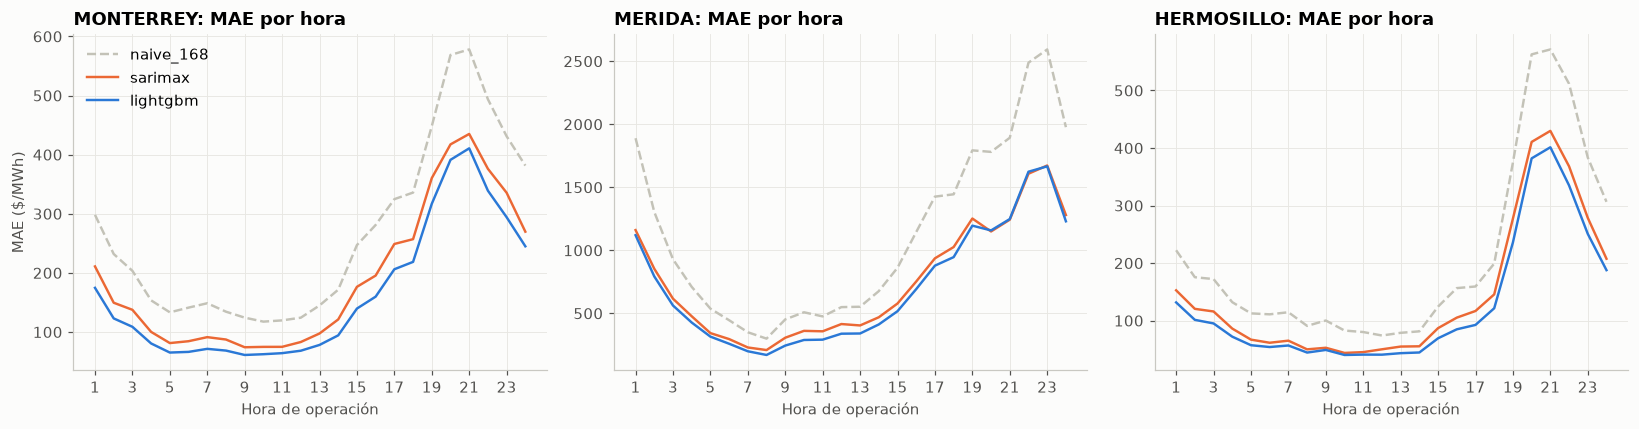

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
estilos = {"naive_168": ("#c3c2b7", "--"), "sarimax": ("#eb6834", "-"), "lightgbm": ("#2a78d6", "-")}
for ax, z in zip(axes, ZONAS_FOCO):
    g = pred[pred.clave == z]
    for m, (c, ls) in estilos.items():
        mae_h = (g["precio"] - g[m]).abs().groupby(g["hora"]).mean()
        ax.plot(mae_h.index, mae_h.values, color=c, ls=ls, label=m)
    ax.set_title(f"{z}: MAE por hora")
    ax.set_xticks(range(1, 25, 2))
    ax.set_xlabel("Hora de operación")
axes[0].set_ylabel("MAE ($/MWh)")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

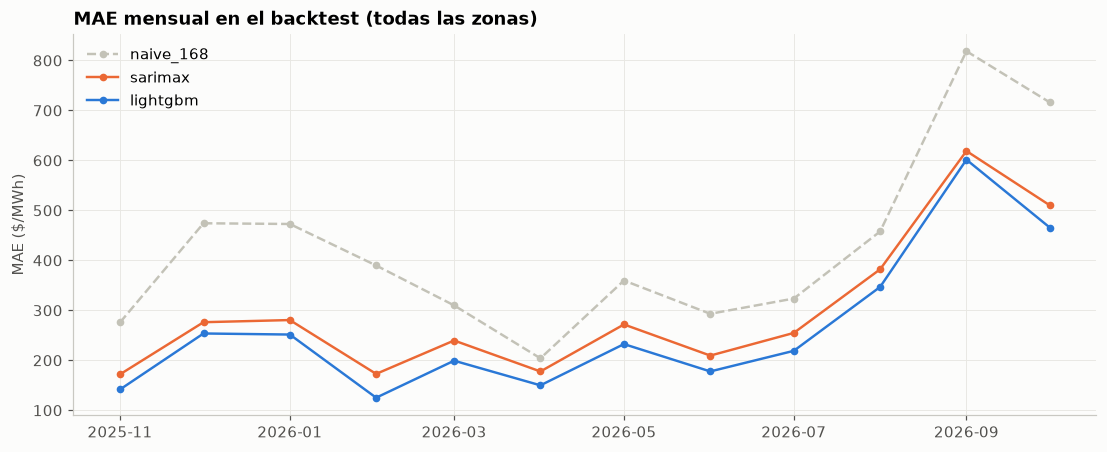

In [15]:
mensual = pred.assign(mes=pred.timestamp.dt.to_period("M")).groupby("mes").apply(
    lambda g: pd.Series({m: (g.precio - g[m]).abs().mean() for m in ["naive_168", "sarimax", "lightgbm"]}))
fig, ax = plt.subplots()
for m, (c, ls) in estilos.items():
    ax.plot(mensual.index.to_timestamp(), mensual[m], color=c, ls=ls, marker="o", ms=4, label=m)
ax.set_title("MAE mensual en el backtest (todas las zonas)")
ax.set_ylabel("MAE ($/MWh)")
ax.legend(loc="upper left")
plt.show()

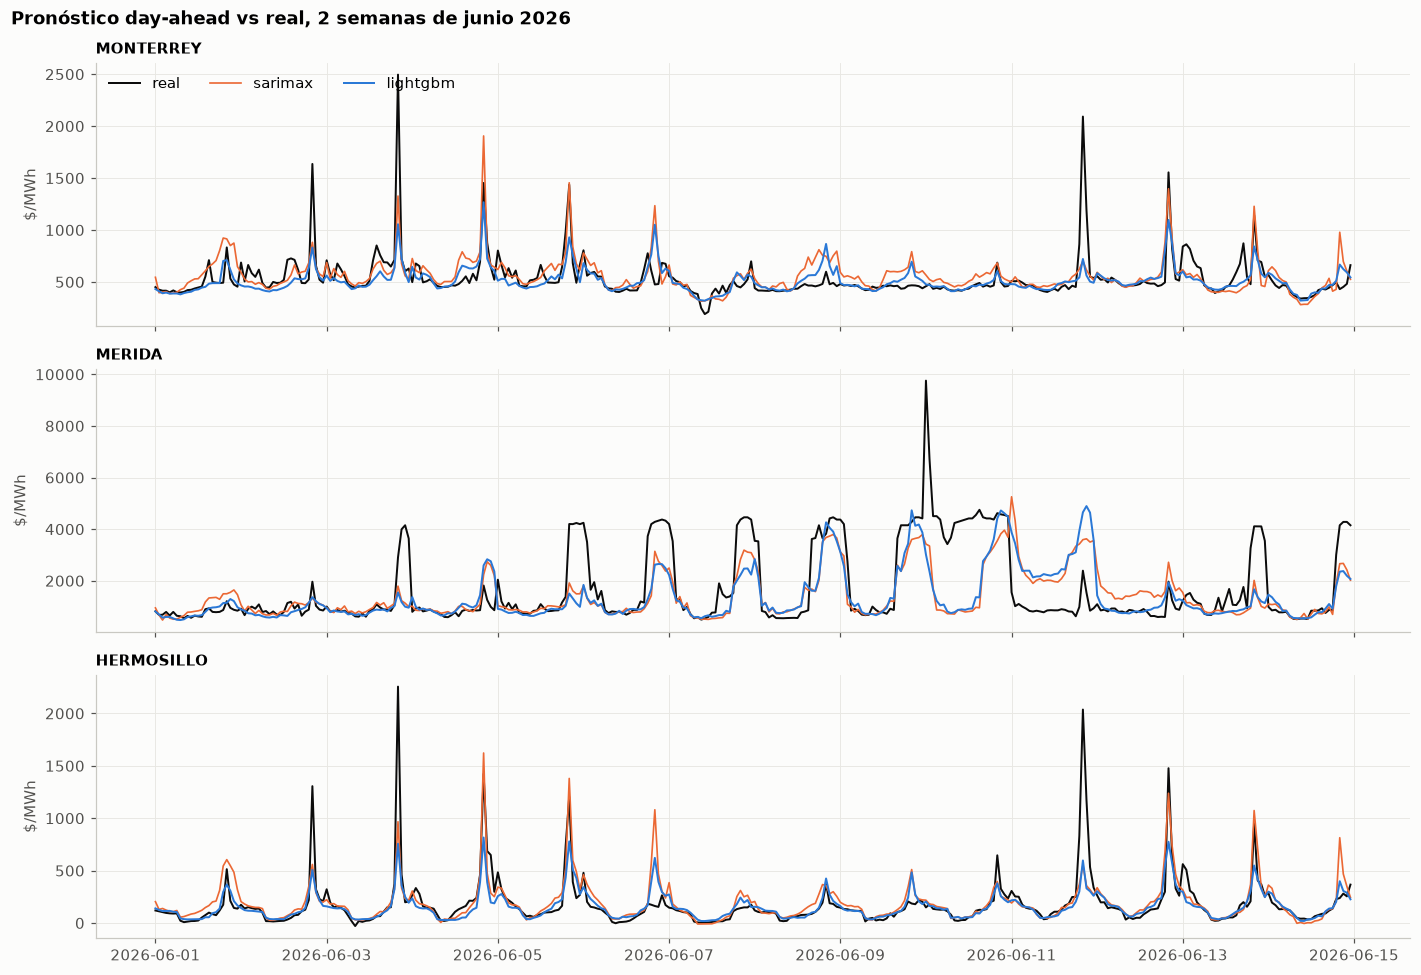

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
ini = pd.Timestamp("2026-06-01")
ventana = pred[(pred.timestamp >= ini) & (pred.timestamp < ini + pd.Timedelta(days=14))]
for ax, z in zip(axes, ZONAS_FOCO):
    g = ventana[ventana.clave == z]
    ax.plot(g.timestamp, g.precio, color="#0b0b0b", lw=1.3, label="real")
    ax.plot(g.timestamp, g.sarimax, color="#eb6834", lw=1.1, label="sarimax")
    ax.plot(g.timestamp, g.lightgbm, color="#2a78d6", lw=1.3, label="lightgbm")
    ax.set_title(z, fontsize=10)
    ax.set_ylabel("$/MWh")
axes[0].legend(loc="upper left", ncol=3)
fig.suptitle("Pronóstico day-ahead vs real, 2 semanas de junio 2026", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Interpretación del modelo

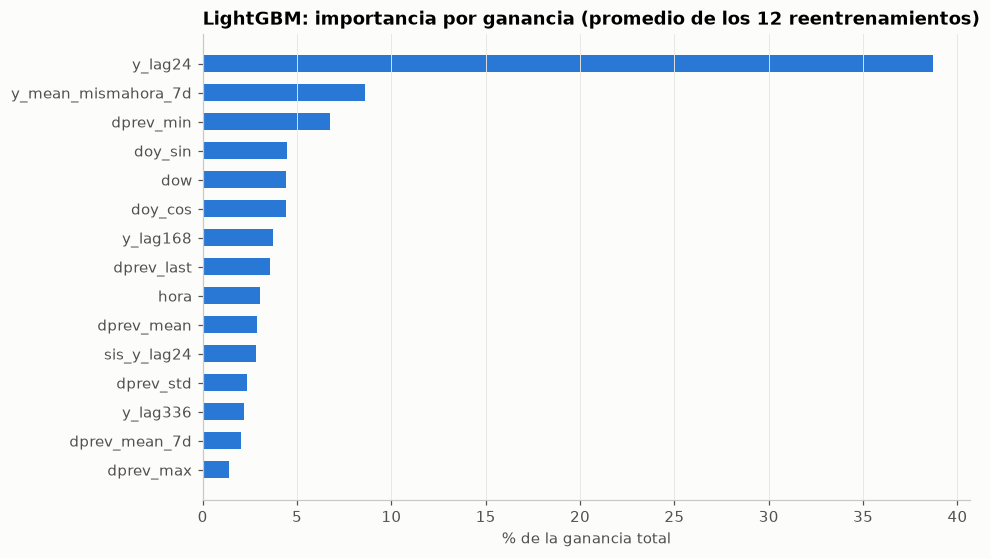

In [17]:
imp = pd.DataFrame({"variable": FEATURES,
                    "ganancia": np.mean([m.booster_.feature_importance("gain") for m in modelos], axis=0)})
imp["ganancia"] = 100 * imp["ganancia"] / imp["ganancia"].sum()
imp = imp.sort_values("ganancia").tail(15)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(imp["variable"], imp["ganancia"], color="#2a78d6", height=0.6)
ax.set_title("LightGBM: importancia por ganancia (promedio de los 12 reentrenamientos)")
ax.set_xlabel("% de la ganancia total")
ax.grid(axis="y", visible=False)
plt.show()

## 6. Ablación: ¿cuánta historia usar?

El EDA mostró cambios de régimen (2018–2019 caro, 2020 barato, curva de pato desde 2023).
Se compara entrenar desde 2017 contra entrenar desde 2022.

In [18]:
t0 = time.time()
p_full, _ = backtest_lgb(pd.Timestamp("2017-01-27"))
comp = pred[["clave", "timestamp", "precio", "lightgbm"]].merge(p_full.rename(columns={"y_hat": "lgb_desde_2017"}), on=["clave", "timestamp"])
abl = comp.groupby("clave").apply(lambda g: pd.Series({
    "MAE desde 2022": (g.precio - g.lightgbm).abs().mean(),
    "MAE desde 2017": (g.precio - g.lgb_desde_2017).abs().mean()}))
abl.loc["TODAS"] = [(comp.precio - comp.lightgbm).abs().mean(), (comp.precio - comp.lgb_desde_2017).abs().mean()]
print(f"{time.time() - t0:.0f} s")
abl.round(1)

255 s


,MAE desde 2022,MAE desde 2017
clave,,
ACAPULCO,278.2,280.5
AGUASCALIENTES,181.2,179.7
GUADALAJARA,188.7,187.6
HERMOSILLO,126.4,125.4
MERIDA,704.9,707.7
MONTERREY,162.9,163.0
PUEBLA,298.0,299.7
QUERETARO,177.9,176.9
TODAS,264.8,265.1


## 7. Guardar

In [19]:
pred.to_parquet(OUT / "predicciones_backtest.parquet", index=False)
metricas(pred).round(3).to_csv(OUT / "metricas_globales.csv")
tabla.to_csv(OUT / "mae_por_zona.csv")
print("Guardado en", OUT.resolve())

Guardado en C:\Users\uriel\Documents\Data Science Proyects\Series_de_tiempo\resultados


## Conclusiones

- **Mejor modelo:** LightGBM global (una sola regresión para las 8 zonas, reentrenada cada mes) es el mejor en todas las zonas, todos los meses y todas las horas del backtest. Su MAE global es de **264.8 $/MWh**, contra 298.2 de SARIMAX y 320.9 del mejor naive. La prueba de Diebold-Mariano confirma que la mejora sobre SARIMAX es significativa (p < 0.001) tanto en el agregado (DM = 8.8) como en cada zona por separado. Además entrena en ~150 s, contra ~920 s de los 192 SARIMAX (8 zonas × 24 horas).

- **Mejora sobre los baselines:** el rMAE es de 0.62 frente a `naive_168`, lo que equivale a una reducción de ~38 % del error, y es muy parecido en todas las zonas (37–39 %). Frente a SARIMAX la mejora es de 12–15 % en casi todas las zonas y de solo 6 % en Mérida. El MAE mediano horario (70 $/MWh) indica que en una hora típica el error es bajo y que la media está inflada por pocas horas extremas. El RMSE de LightGBM y SARIMAX es casi el mismo (687 vs 689): ninguno de los dos resuelve los picos grandes.

- **Dónde falla:**
  - *Horas:* el error se concentra en la rampa vespertina y la noche (horas 17–24, MAE de 340–560), cuando sale la generación solar (curva de pato). En las horas de la mañana y del mediodía (6–11) el MAE es de 90–115.
  - *Zonas:* Mérida es por mucho la peor (MAE de 705, un 47 % de su precio medio). Ahí los precios saltan durante varias horas de golpe, de ~1 000 a ~4 000 $/MWh (congestión de la península), y el modelo solo ve esos episodios con un día de retraso. Hermosillo tiene el MAE absoluto más bajo, pero un error relativo alto (37 %) porque sus precios son bajos y tienen picos aislados.
  - *Meses:* septiembre y octubre de 2026 son los peores (MAE de 600 y 465) y en ellos la ventaja sobre SARIMAX casi desaparece (3 % en septiembre). En febrero, con precios estables, la mejora llega al 28 %.
  - *Picos:* el 5 % de las horas con mayor error acumula el 45 % del error absoluto total. En las horas por encima del p95 de cada zona LightGBM subestima sistemáticamente (sesgo de +1 740 $/MWh) y queda incluso un poco por detrás de SARIMAX. La pérdida L1 apunta a la mediana, así que el modelo suaviza los picos, y en promedio subestima el precio en 106 $/MWh.

- **Qué aporta más al modelo:** domina la persistencia. `y_lag24` concentra ~39 % de la ganancia, seguida del promedio de la misma hora en los últimos 7 días (~9 %) y del mínimo del día previo (~7 %). Después vienen la estacionalidad anual (`doy_sin/cos`), el día de la semana y el lag semanal. Las componentes de congestión, pérdidas y energía rezagadas no aparecen entre las 15 variables más importantes: lo que publica el MDA con 24 h de rezago aporta poco más allá del propio precio.

- **Historia completa vs reciente:** entrenar desde 2017 o desde 2022 da prácticamente lo mismo (MAE de 265.1 vs 264.8; las diferencias por zona son menores a ±2 $/MWh). Con la normalización por mediana de cada zona y la variable `doy`, el modelo absorbe los cambios de régimen, y la historia antigua ni ayuda ni estorba. Se queda 2022 como punto de partida porque es más barato de entrenar.

- **Siguientes pasos:**
  - Pronóstico probabilístico (cuantiles p10–p90 con LightGBM `objective="quantile"`) para cuantificar el riesgo de los picos, que el pronóstico puntual no captura.
  - Exógenas que anticipen los picos en lugar de reaccionar a ellos: temperatura pronosticada, demanda pronosticada por CENACE, disponibilidad de generación y estado de la red (en especial para la península de Yucatán).
  - Un modelo o tratamiento específico para Mérida (por ejemplo, un clasificador de "día de congestión" que alimente el regresor).
  - Ponderar más las horas 17–24 o entrenar modelos por bloque horario, ya que ahí está la mayor parte del error.